# Hotel Revenue Protection: Cancellation Predictor

## 1. Problem Framing

### Business Problem
Hotels lose potential revenue when customers cancel their reservations, especially when cancellations happen close to the arrival date.

### Project Objective
The objective of this project is to develop a Machine Learning classification model that predicts whether a hotel booking will be canceled.

The model will help hotels make better decisions about:
- Managing booking cancellations.
- Reducing potential revenue losses.
- Applying suitable deposit policies.
- Improving room availability and revenue planning.

### Target Variable
`is_canceled`

- `0`: Booking is not canceled.
- `1`: Booking is canceled.

### Business Decision
Based on the predicted cancellation probability, the application will recommend one of three deposit policies:

- No deposit.
- Partial deposit.
- Full deposit.

### Evaluation Strategy
We will compare multiple classification algorithms and evaluate them using Accuracy, Precision, Recall, F1-score, ROC-AUC, and a Confusion Matrix.

Recall for the canceled class is particularly important because failing to identify a booking that will be canceled can lead to poor hotel planning.

## Dataset Source

Hotel Booking Demand dataset from Kaggle:
https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand

The original dataset contains approximately 119,390 booking records and 32 columns.

## 1. Import libraries

In [133]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report
from sklearn.metrics import roc_curve, auc
import joblib

# Load dataset and Understanding

In [2]:
df = pd.read_csv("hotel_bookings.csv")

df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


# Data Understanding

In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 119390
Number of columns: 32


In [4]:
print("Dataset Columns:")
for column in df.columns:
    print(column)

Dataset Columns:
hotel
is_canceled
lead_time
arrival_date_year
arrival_date_month
arrival_date_week_number
arrival_date_day_of_month
stays_in_weekend_nights
stays_in_week_nights
adults
children
babies
meal
country
market_segment
distribution_channel
is_repeated_guest
previous_cancellations
previous_bookings_not_canceled
reserved_room_type
assigned_room_type
booking_changes
deposit_type
agent
company
days_in_waiting_list
customer_type
adr
required_car_parking_spaces
total_of_special_requests
reservation_status
reservation_status_date


In [136]:
column_dictionary = pd.DataFrame({
    "Column": X.columns,
    "Data Type": X.dtypes.astype(str).values,
    "Description": ""
})

column_dictionary

,Column,Data Type,Description
0,hotel,object,
1,lead_time,int64,
2,stays_in_weekend_nights,int64,
3,stays_in_week_nights,int64,
4,adults,int64,
5,children,float64,
6,babies,int64,
7,meal,object,
8,country,object,
9,market_segment,object,


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [6]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,119390.0,NaN,NaN,NaN,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,NaN,NaN,NaN,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,NaN,NaN,NaN,2016.156554,0.707476,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,119390.0,NaN,NaN,NaN,27.165173,13.605138,1.0,16.0,28.0,38.0,53.0
arrival_date_day_of_month,119390.0,NaN,NaN,NaN,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,NaN,NaN,NaN,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,NaN,NaN,NaN,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0
adults,119390.0,NaN,NaN,NaN,1.856403,0.579261,0.0,2.0,2.0,2.0,55.0


In [7]:
missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})
missing_values = missing_values.sort_values(by="Missing Percentage", ascending=False)
missing_values

,Missing Values,Missing Percentage
company,112593,94.306893
agent,16340,13.686238
country,488,0.408744
children,4,0.003350
arrival_date_month,0,0.000000
arrival_date_week_number,0,0.000000
hotel,0,0.000000
is_canceled,0,0.000000
stays_in_weekend_nights,0,0.000000
arrival_date_day_of_month,0,0.000000


In [8]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 31994


In [11]:
target = df["is_canceled"].value_counts()
target_percent = df["is_canceled"].value_counts(normalize=True) * 100
print(target)
print("Target percentages: ",target_percent)

is_canceled
0    75166
1    44224
Name: count, dtype: int64
Target percentages:  is_canceled
0    62.958372
1    37.041628
Name: proportion, dtype: float64


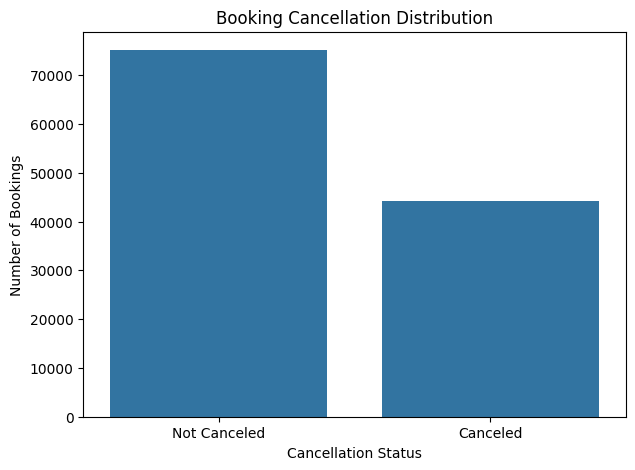

In [13]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="is_canceled")

plt.title("Booking Cancellation Distribution")
plt.xlabel("Cancellation Status")
plt.ylabel("Number of Bookings")
plt.xticks([0, 1], ["Not Canceled", "Canceled"])

plt.show()

## 2 — Exploratory Data Analysis (EDA)

In [14]:
duplicates = df[df.duplicated(keep=False)]
print("Total rows involved in duplicates: ",len(duplicates))
duplicates.head()

Total rows involved in duplicates:  40165


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
21,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
39,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,2015-07-07


In [15]:
duplicate_groups = (df.groupby(list(df.columns)).size().reset_index(name="count"))
duplicate_groups[duplicate_groups["count"] > 1].head(10)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,count
4,City Hotel,0,0,2015,August,33,13,0,2,2,...,9.0,9.0,0,Transient,85.00,0,0,Check-Out,2015-08-15,2
35,City Hotel,0,256,2016,October,43,16,2,3,2,...,9.0,333.0,0,Transient-Party,100.75,0,0,Check-Out,2016-10-21,7
36,City Hotel,0,256,2016,October,43,16,2,3,2,...,9.0,333.0,0,Transient-Party,100.75,0,0,Check-Out,2016-10-21,2
55,Resort Hotel,0,5,2017,January,1,2,1,3,1,...,314.0,29.0,0,Transient-Party,40.40,1,1,Check-Out,2017-01-06,2
90,Resort Hotel,0,24,2015,November,45,3,3,10,1,...,334.0,281.0,0,Transient-Party,40.00,0,0,Check-Out,2015-11-16,5
95,Resort Hotel,0,24,2015,November,45,3,3,10,2,...,326.0,281.0,0,Transient,48.00,0,0,Check-Out,2015-11-16,2
98,Resort Hotel,0,24,2015,October,44,26,7,15,1,...,185.0,281.0,0,Transient-Party,52.20,0,0,Check-Out,2015-11-17,2
102,Resort Hotel,0,27,2015,November,45,6,2,7,1,...,334.0,281.0,0,Transient-Party,40.00,0,0,Check-Out,2015-11-15,2
110,Resort Hotel,0,31,2015,November,45,2,3,10,1,...,185.0,281.0,0,Transient-Party,36.00,0,0,Check-Out,2015-11-15,2
115,Resort Hotel,0,31,2015,November,45,2,5,10,1,...,185.0,281.0,0,Transient-Party,52.20,0,0,Check-Out,2015-11-17,2


### Univariate analysis — Numerical features

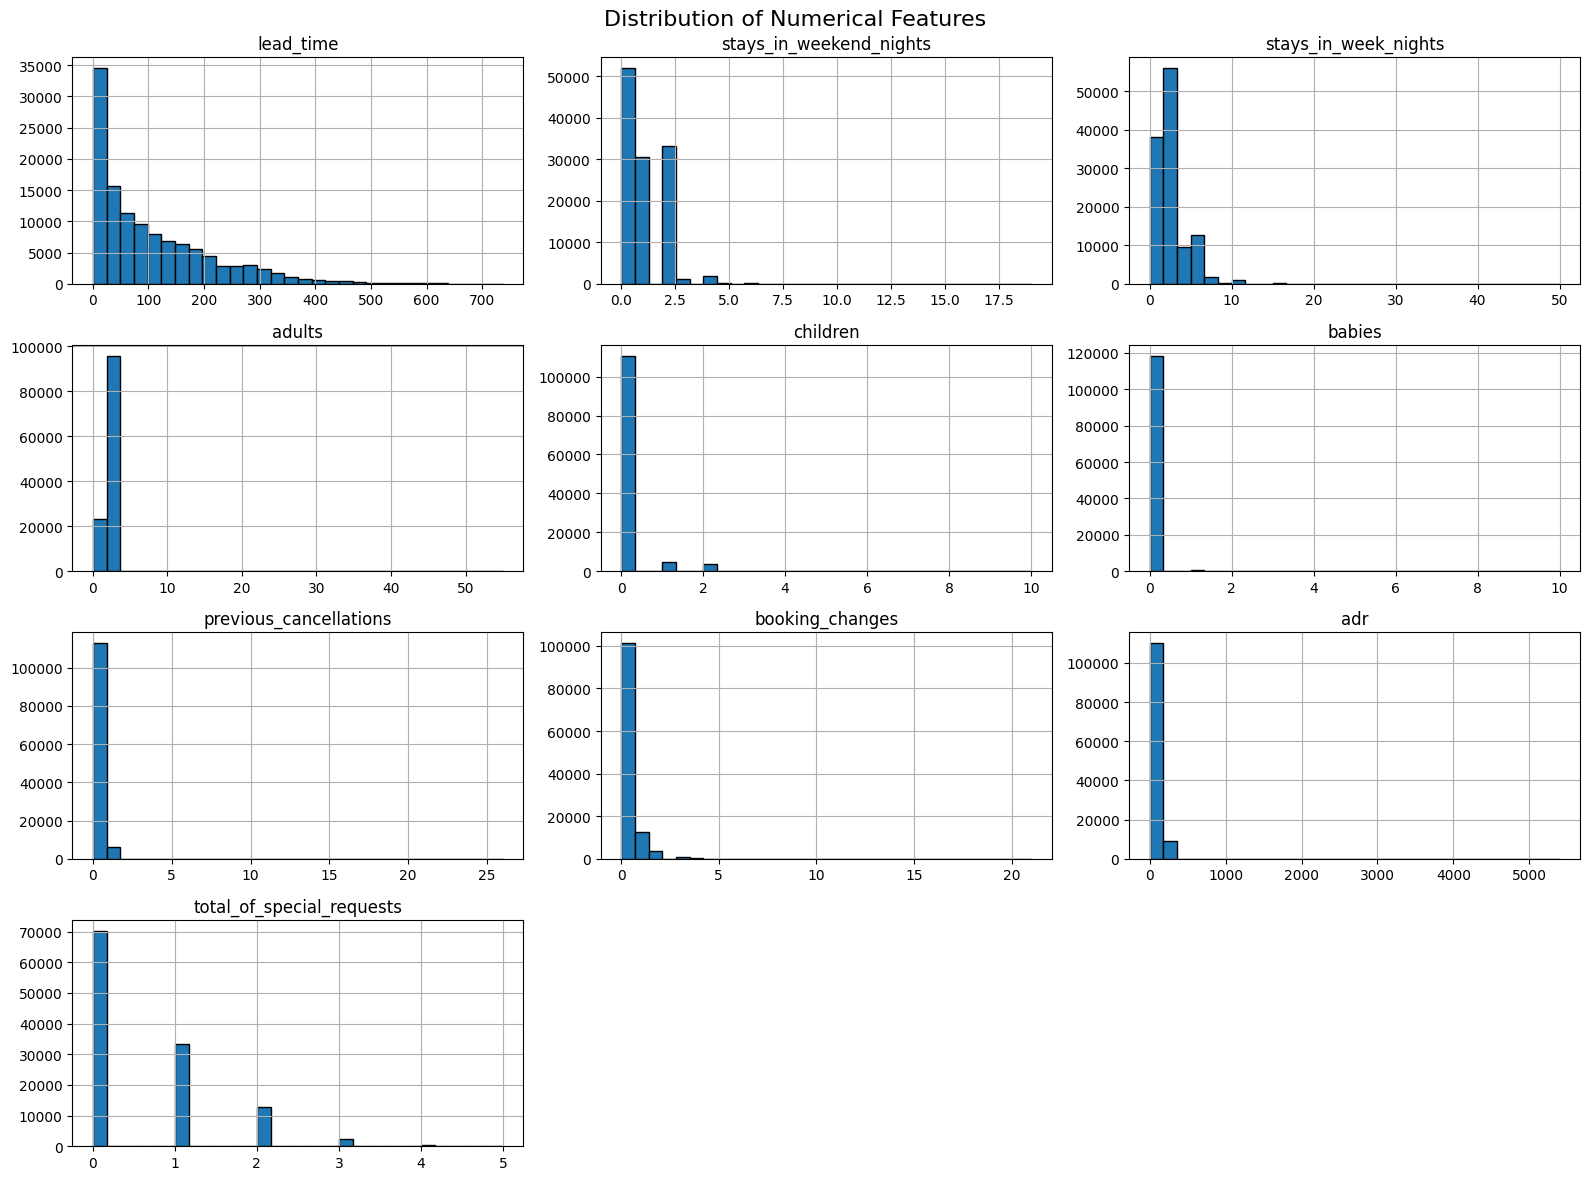

In [18]:
numerical_columns = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "previous_cancellations",
    "booking_changes",
    "adr",
    "total_of_special_requests"
]
df[numerical_columns].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)
plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

### Univariate analysis — Categorical features

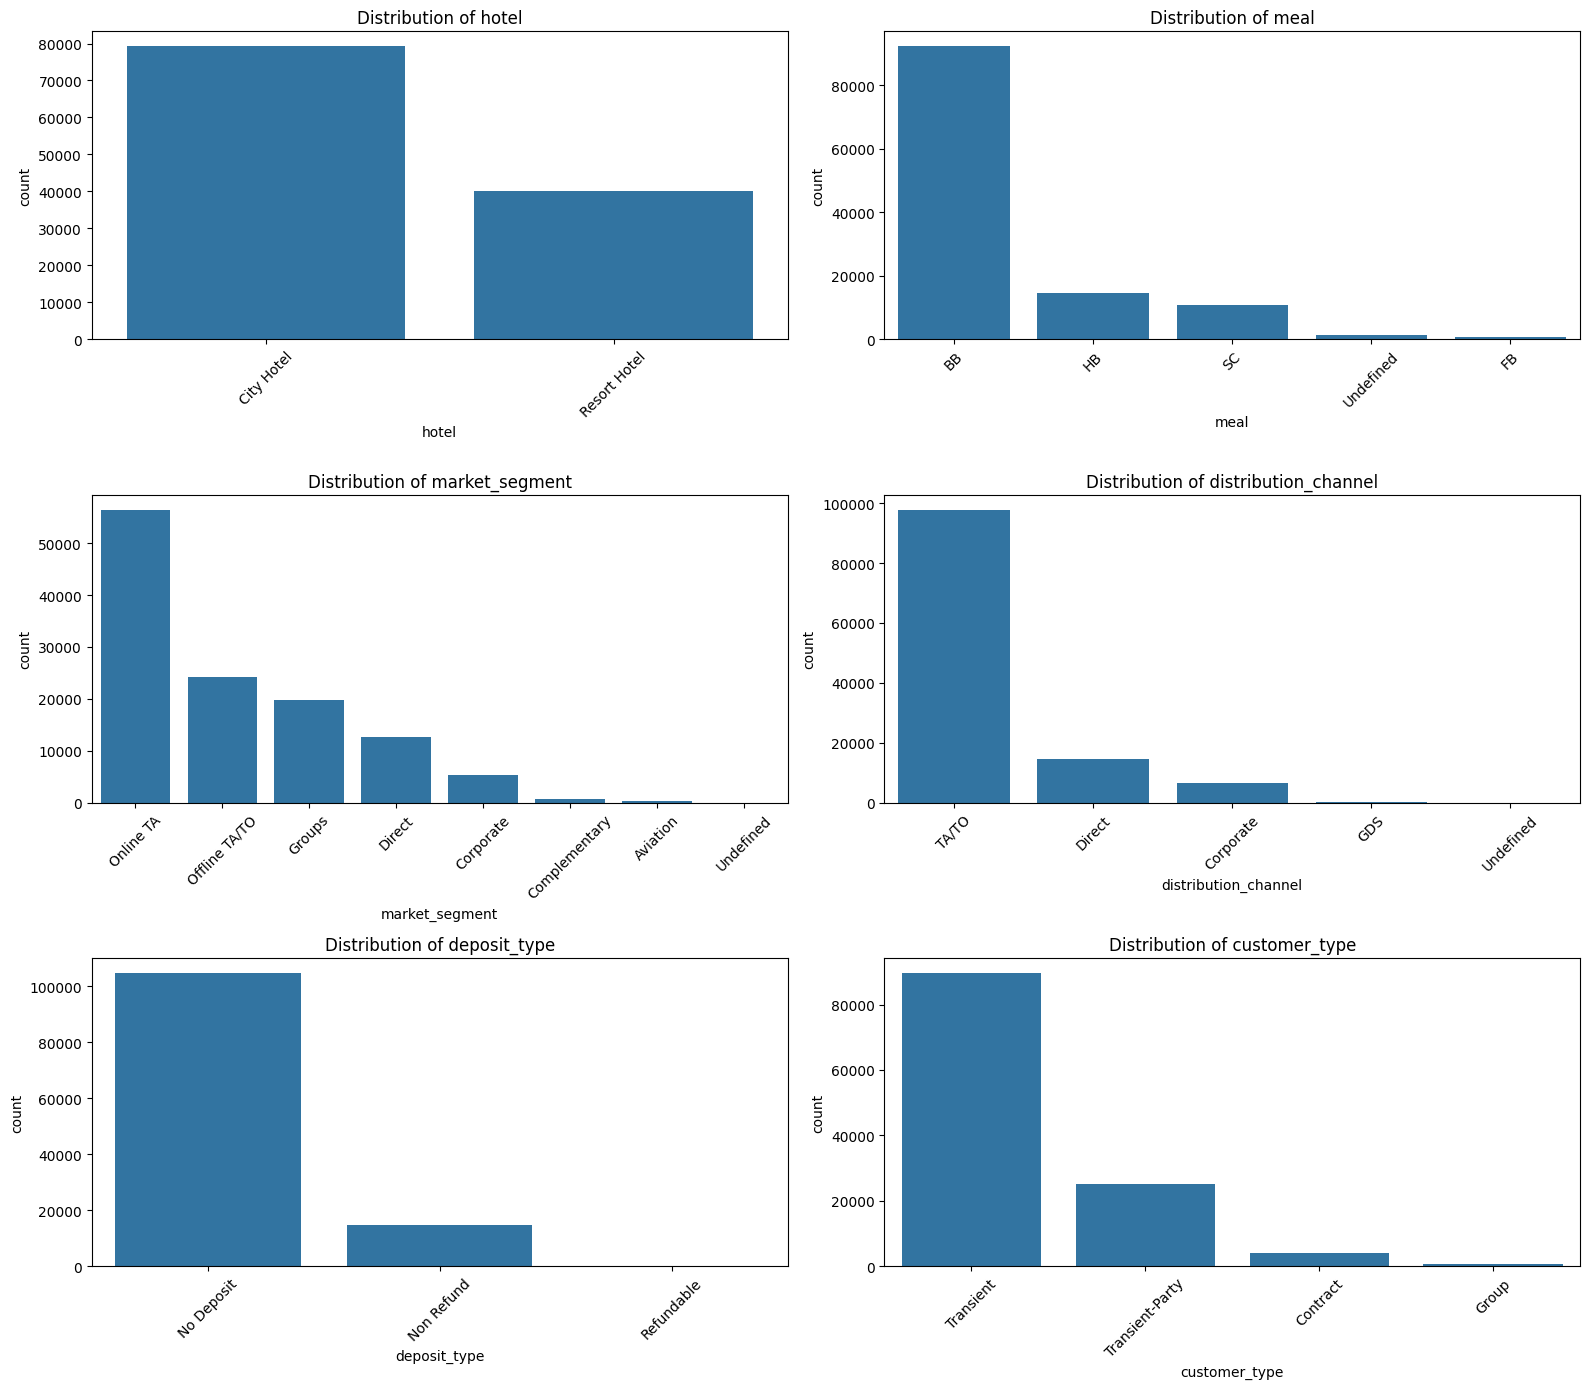

In [23]:
categorical_columns = [
    "hotel",
    "meal",
    "market_segment",
    "distribution_channel",
    "deposit_type",
    "customer_type"
]
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
for column, ax in zip(categorical_columns, axes.flatten()):
    sns.countplot(
        data=df,
        x=column,
        ax=ax,
        order=df[column].value_counts().index
    )

    ax.set_title(f"Distribution of {column}")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### Bivariate analysis — Relationship with cancellation

#### Cancellation by hotel type

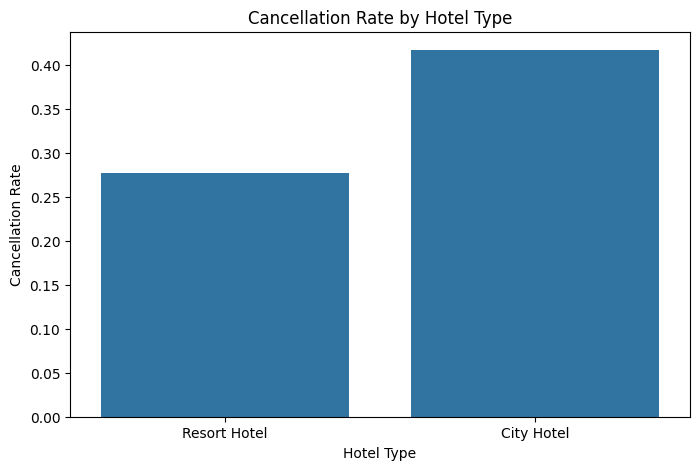

In [24]:
plt.figure(figsize=(8,5))
sns.barplot(data=df,x="hotel",y="is_canceled",errorbar=None)

plt.title("Cancellation Rate by Hotel Type")
plt.ylabel("Cancellation Rate")
plt.xlabel("Hotel Type")
plt.show()

#### Cancellation by deposit type

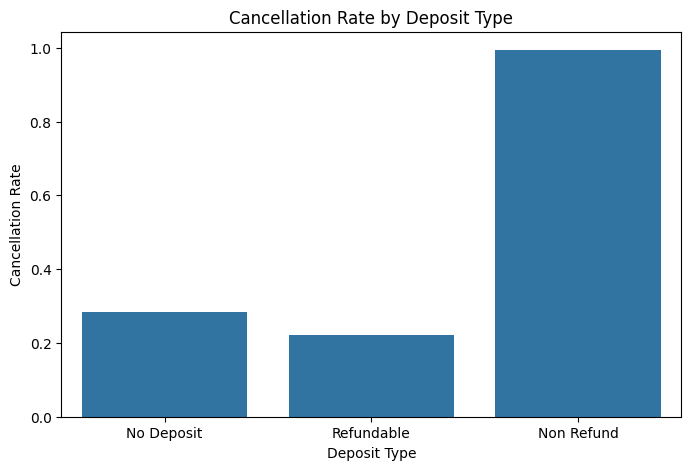

In [25]:
plt.figure(figsize=(8,5))
sns.barplot(data=df,x="deposit_type",y="is_canceled",errorbar=None)

plt.title("Cancellation Rate by Deposit Type")
plt.ylabel("Cancellation Rate")
plt.xlabel("Deposit Type")
plt.show()

#### Cancellation by market segment

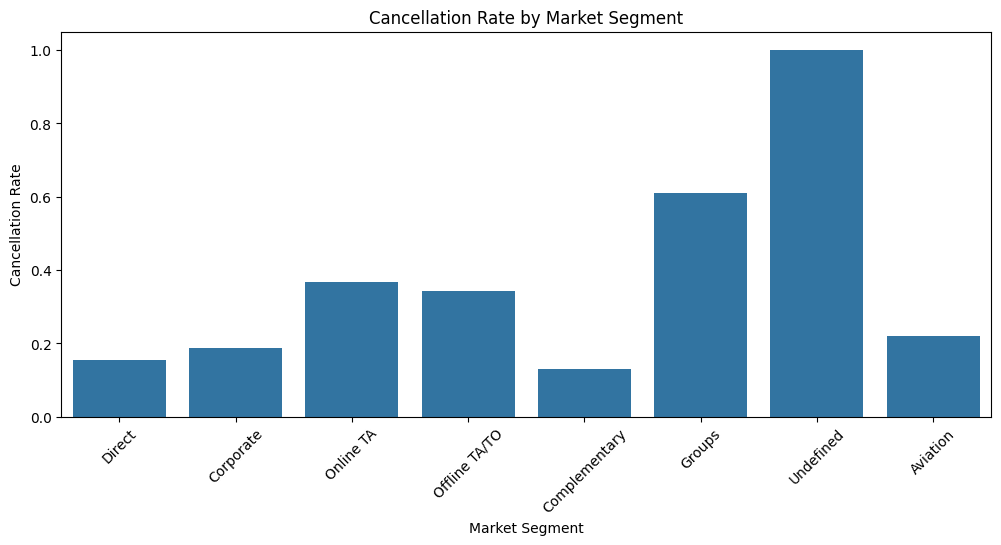

In [26]:
plt.figure(figsize=(12,5))
sns.barplot(data=df,x="market_segment",y="is_canceled",errorbar=None)

plt.title("Cancellation Rate by Market Segment")
plt.ylabel("Cancellation Rate")
plt.xlabel("Market Segment")
plt.xticks(rotation=45)
plt.show()

#### Lead time and cancellation

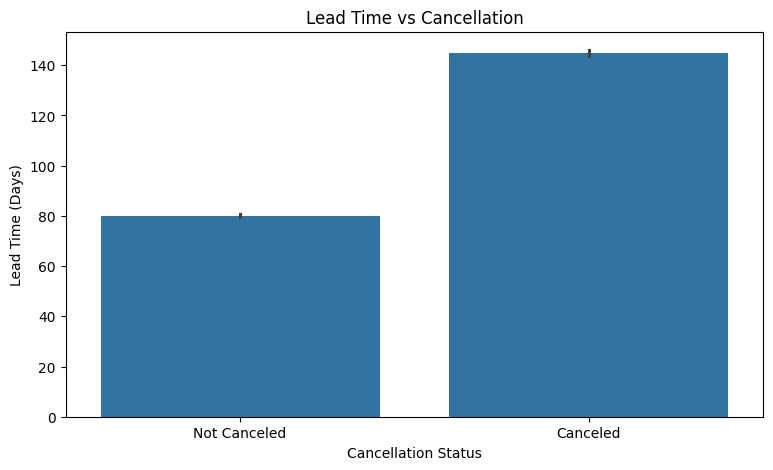

In [29]:
plt.figure(figsize=(9,5))
sns.barplot(data=df,y="lead_time",x="is_canceled")

plt.title("Lead Time vs Cancellation")
plt.xlabel("Cancellation Status")
plt.ylabel("Lead Time (Days)")
plt.xticks([0,1],["Not Canceled","Canceled"])
plt.show()

#### Cancellation by customer type

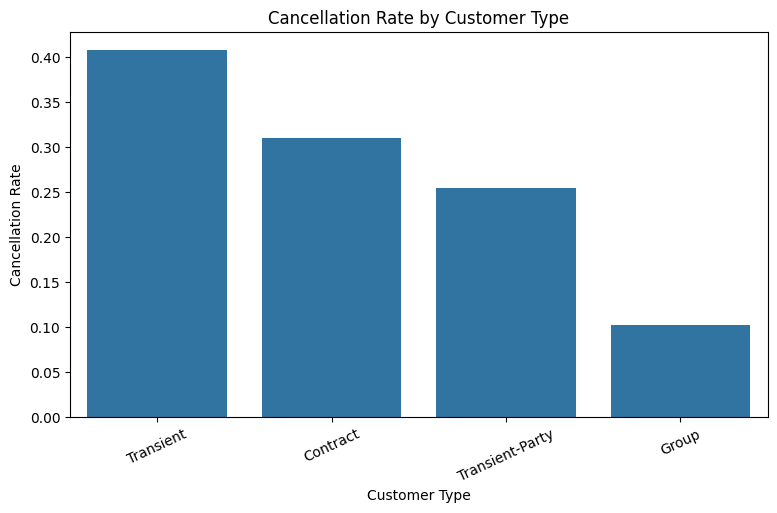

In [32]:
plt.figure(figsize=(9,5))
sns.barplot(data=df,x="customer_type",y="is_canceled",errorbar=None)

plt.title("Cancellation Rate by Customer Type")
plt.ylabel("Cancellation Rate")
plt.xlabel("Customer Type")
plt.xticks(rotation=25)
plt.show()

### Multivariate analysis — Correlation heatmap

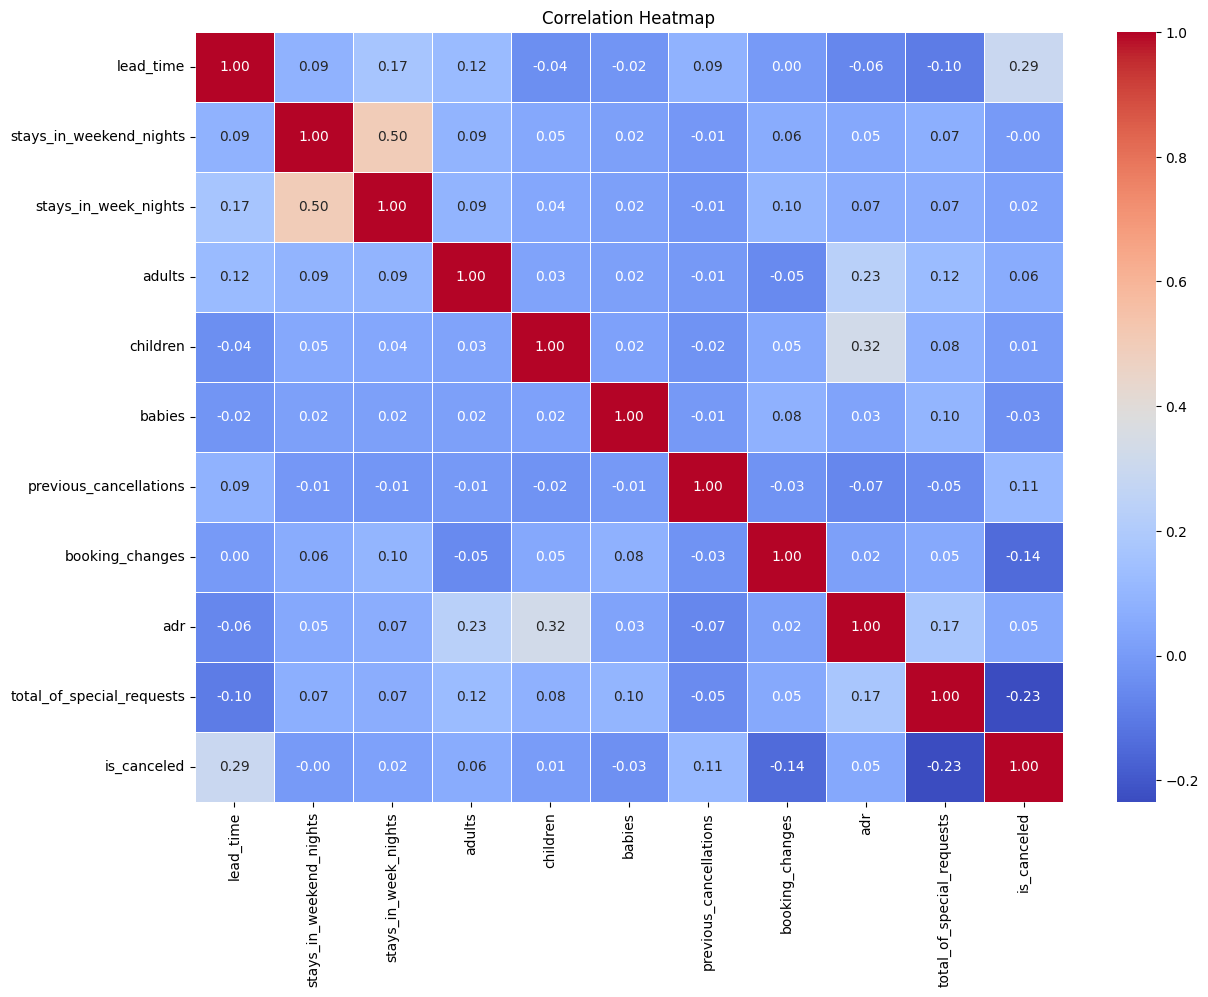

In [33]:
plt.figure(figsize=(14,10))
correlation = df[numerical_columns + ["is_canceled"]].corr()

sns.heatmap(correlation,annot=True,cmap="coolwarm",fmt=".2f",linewidths=0.5)

plt.title("Correlation Heatmap")
plt.show()

#### Investigate cancellation by arrival month

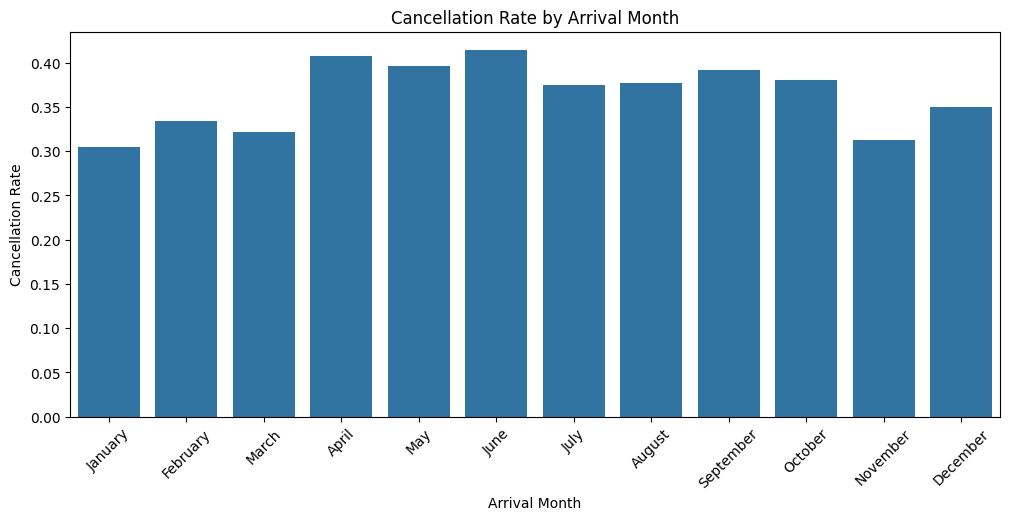

In [34]:
month_order = ["January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"]

monthly_cancellation = (df.groupby("arrival_date_month")["is_canceled"].mean().reindex(month_order))

plt.figure(figsize=(12,5))
sns.barplot(x=monthly_cancellation.index,y=monthly_cancellation.values)

plt.title("Cancellation Rate by Arrival Month")
plt.xlabel("Arrival Month")
plt.ylabel("Cancellation Rate")
plt.xticks(rotation = 45)
plt.show()

#### Important leakage warning

In [35]:
leakage_columns = ["reservation_status","reservation_status_date"]

print("Columns to exclude: ")
print(leakage_columns)

# reservation_status directly reveals the booking's final status. 
# reservation_status_date is also associated with the final outcome and should not be used as a prediction feature.

Columns to exclude: 
['reservation_status', 'reservation_status_date']


## Data Cleaning and Preprocessing

In [59]:
df_clean = df.copy()
print("Original dataset shape: ",df.shape)
print("Working dataset shape: ",df_clean.shape)

Original dataset shape:  (119390, 32)
Working dataset shape:  (119390, 32)


#### Handle duplicate

In [60]:
print("Before removing duplicates: ", df_clean.shape)
print("Duplicates: ", df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates()
print("After removing duplicates: ", df_clean.shape)
print("Remaining duplicates: ",df_clean.duplicated().sum())

Before removing duplicates:  (119390, 32)
Duplicates:  31994
After removing duplicates:  (87396, 32)
Remaining duplicates:  0


#### Remove leakage and unsuitable columns

In [61]:
columns_to_drop = ["reservation_status",
    "reservation_status_date",
    "assigned_room_type",
    "booking_changes",
    "days_in_waiting_list",
    "company",
    "agent",
    "deposit_type"]
df_clean = df_clean.drop(columns=columns_to_drop)
print("Remaining columns: ", len(df_clean.columns))
print(df_clean.columns.tolist())

Remaining columns:  24
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']


#### Handle missing values

In [62]:
missing = df_clean.isnull().sum()
missing = missing[missing>0]
print(missing)

children      4
country     452
dtype: int64


In [63]:
# Handle categorical missing
df_clean["country"] = df_clean["country"].fillna("Unknown")

# Handle numerical missing
df_clean["children"] = df_clean["children"].fillna(df_clean["children"].median())

print("Remaining missing values: ", df_clean.isnull().sum().sum())

Remaining missing values:  0


#### Check invalid values and outliers

In [64]:
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,87396.0,0.274898,0.446466,0.00,0.0,0.0,1.0,1.0
lead_time,87396.0,79.891368,86.052325,0.00,11.0,49.0,125.0,737.0
arrival_date_year,87396.0,2016.210296,0.686102,2015.00,2016.0,2016.0,2017.0,2017.0
arrival_date_week_number,87396.0,26.838334,13.674572,1.00,16.0,27.0,37.0,53.0
arrival_date_day_of_month,87396.0,15.815541,8.835146,1.00,8.0,16.0,23.0,31.0
stays_in_weekend_nights,87396.0,1.005263,1.031921,0.00,0.0,1.0,2.0,19.0
stays_in_week_nights,87396.0,2.625395,2.053584,0.00,1.0,2.0,4.0,50.0
adults,87396.0,1.875795,0.626500,0.00,2.0,2.0,2.0,55.0
children,87396.0,0.138633,0.455871,0.00,0.0,0.0,0.0,10.0
babies,87396.0,0.010824,0.113597,0.00,0.0,0.0,0.0,10.0


In [65]:
invalid_guests = df_clean[(df_clean["adults"] + df_clean["children"] + df_clean["babies"]) == 0]

print("Bookings with zero guests:", len(invalid_guests))

Bookings with zero guests: 166


#### Check unusual ADR values

In [66]:
print("Minimum ADR:", df_clean["adr"].min())
print("Maximum ADR:", df_clean["adr"].max())
print("Negative ADR records: ",(df_clean["adr"]<0).sum())

Minimum ADR: -6.38
Maximum ADR: 5400.0
Negative ADR records:  1


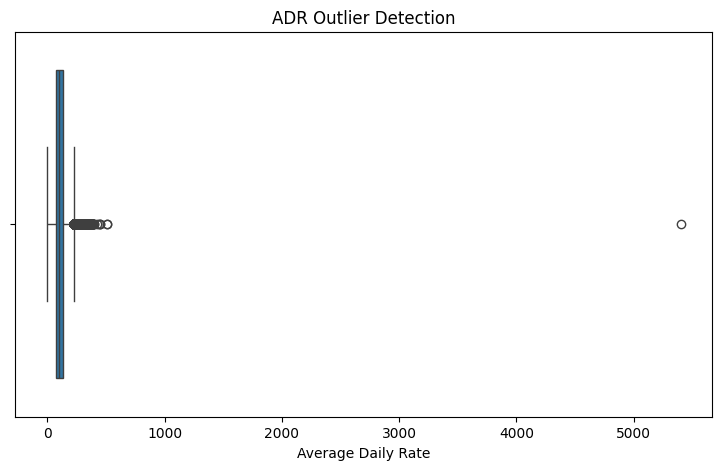

In [67]:
plt.figure(figsize=(9,5))
sns.boxplot(x=df_clean["adr"])
plt.title("ADR Outlier Detection")
plt.xlabel("Average Daily Rate")
plt.show()

#### Feature Engineering — Arrival Date
The original dataset stores the arrival date in three separate columns:
- arrival_date_year
- arrival_date_month
- arrival_date_day_of_month

##### combine these into one proper date feature

In [68]:
# convert month names to numbers
month_mapping = {"January": 1,
    "February": 2,
    "March": 3,
    "April": 4,
    "May": 5,
    "June": 6,
    "July": 7,
    "August": 8,
    "September": 9,
    "October": 10,
    "November": 11,
    "December": 12}

df_clean["arrival_month"] = ( df_clean["arrival_date_month"].map(month_mapping))

df_clean["arrival_date"] = pd.to_datetime({
    "year": df_clean["arrival_date_year"],
    "month": df_clean["arrival_month"],
    "day": df_clean["arrival_date_day_of_month"]
})

# extract useful features
df_clean["arrival_day_of_week"] = df_clean["arrival_date"].dt.dayofweek
df_clean["arrival_month_num"] = df_clean["arrival_date"].dt.month

# calc total nights
df_clean["total_nights"] = (df_clean["stays_in_weekend_nights"] + df_clean["stays_in_week_nights"])

# calc total guest
df_clean["total_guests"] = (df_clean["adults"] + df_clean["children"] + df_clean["babies"])

df_clean.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,customer_type,adr,required_car_parking_spaces,total_of_special_requests,arrival_month,arrival_date,arrival_day_of_week,arrival_month_num,total_nights,total_guests
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,Transient,0.0,0,0,7,2015-07-01,2,7,0,2.0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,Transient,0.0,0,0,7,2015-07-01,2,7,0,2.0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,Transient,75.0,0,0,7,2015-07-01,2,7,1,1.0
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,Transient,75.0,0,0,7,2015-07-01,2,7,1,1.0
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,Transient,98.0,0,1,7,2015-07-01,2,7,2,2.0


In [69]:
# remove original date columns

df_clean = df_clean.drop(columns=["arrival_date_year","arrival_date_month",
    "arrival_date_week_number",
    "arrival_date_day_of_month",
    "arrival_month",
    "arrival_date"])

print(df_clean.shape)

(87396, 24)


#### Separate Features and Target

In [71]:
X = df_clean.drop(columns=["is_canceled"])
y = df_clean["is_canceled"]

print("Features shape: ", X.shape) # info about hotel booking
print("Target shape: ", y.shape)  # whether booking was canceled

print("\nTarget distribution: ", y.value_counts(normalize=True) * 100)

Features shape:  (87396, 23)
Target shape:  (87396,)

Target distribution:  is_canceled
0    72.510184
1    27.489816
Name: proportion, dtype: float64


#### Split the Dataset 80% Training data & 20% Testing Data

In [74]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print("Training features: ", X_train.shape)
print("Testing features: ", X_test.shape)

print("\nTraining target distribution: ", y_train.value_counts(normalize=True))
print("\nTesting target distribution: ", y_test.value_counts(normalize=True))


Training features:  (69916, 23)
Testing features:  (17480, 23)

Training target distribution:  is_canceled
0    0.725099
1    0.274901
Name: proportion, dtype: float64

Testing target distribution:  is_canceled
0    0.725114
1    0.274886
Name: proportion, dtype: float64


#### Build the preprocessing pipeline

##### Rebuild the cleaned dataset
Because we want to move imputation inside the pipeline, start again from the original df, not imputed df_clean

In [75]:
# start form original dataset 
df_model = df.copy()

# remove duplicate
df_model = df_model.drop_duplicates()

#remove leakage and unsuitable col
df_model = df_model.drop(columns=columns_to_drop)
print("Shape after removing duplicates and columns: ",df_model.shape)

Shape after removing duplicates and columns:  (87396, 24)


#### Inspect invalid records

In [94]:
invalid_guests = (
    df["adults"] +
    df["children"].fillna(0) +
    df["babies"]
) == 0

print("Zero guest bookings:", invalid_guests.sum())
invalid_guests.head()

Zero guest bookings: 180


0    False
1    False
2    False
3    False
4    False
dtype: bool

#### Inspect negative ADR

In [77]:
negative_adr = df_model[df_model["adr"] < 0]
print("Negative ADR records: ", len(negative_adr))
negative_adr

Negative ADR records:  1


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,customer_type,adr,required_car_parking_spaces,total_of_special_requests
14969,Resort Hotel,0,195,2017,March,10,5,4,6,2,...,Groups,Direct,1,0,2,A,Transient-Party,-6.38,0,0


In [78]:
# Remove invalid records
df_model = df_model[(df_model["adults"] + df_model["children"].fillna(0) + df_model["babies"]) > 0]

df_model = df_model[df_model["adr"] >= 0]
print("Shape after removing invalid records: ", df_model.shape)

Shape after removing invalid records:  (87229, 24)


In [79]:
df_model.nlargest(10,"adr")[["hotel","adr","adults","children","stays_in_week_nights",
                             "stays_in_weekend_nights"]]

,hotel,adr,adults,children,stays_in_week_nights,stays_in_weekend_nights
48515,City Hotel,5400.00,2,0.0,1,0
111403,City Hotel,510.00,1,0.0,1,0
15083,Resort Hotel,508.00,2,0.0,1,0
103912,City Hotel,451.50,2,2.0,1,1
13142,Resort Hotel,450.00,2,0.0,10,4
13391,Resort Hotel,437.00,2,2.0,4,2
39155,Resort Hotel,426.25,2,2.0,6,2
39568,Resort Hotel,402.00,3,1.0,3,2
39118,Resort Hotel,397.38,3,2.0,5,3
13323,Resort Hotel,392.00,2,1.0,8,2


#### Feature Engineering

Recreate the arrival-date features:

In [80]:
df_model["arrival_month"] = ( df_model["arrival_date_month"].map(month_mapping))

df_model["arrival_date"] = pd.to_datetime({
    "year": df_model["arrival_date_year"],
    "month": df_model["arrival_month"],
    "day": df_model["arrival_date_day_of_month"]
})

df_model["arrival_day_of_week"] = df_model["arrival_date"].dt.dayofweek
df_model["arrival_month_num"] = df_model["arrival_date"].dt.month

df_model["total_nights"] = (df_model["stays_in_weekend_nights"] + df_model["stays_in_week_nights"])

df_model["total_guests"] = (df_model["adults"] + df_model["children"] + df_model["babies"])

# Remove original date columns
df_model = df_model.drop(columns=[
    "arrival_date_year",
    "arrival_date_month",
    "arrival_date_week_number",
    "arrival_date_day_of_month",
    "arrival_month",
    "arrival_date"
])
df_model.head()

,hotel,is_canceled,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,...,previous_bookings_not_canceled,reserved_room_type,customer_type,adr,required_car_parking_spaces,total_of_special_requests,arrival_day_of_week,arrival_month_num,total_nights,total_guests
0,Resort Hotel,0,342,0,0,2,0.0,0,BB,PRT,...,0,C,Transient,0.0,0,0,2,7,0,2.0
1,Resort Hotel,0,737,0,0,2,0.0,0,BB,PRT,...,0,C,Transient,0.0,0,0,2,7,0,2.0
2,Resort Hotel,0,7,0,1,1,0.0,0,BB,GBR,...,0,A,Transient,75.0,0,0,2,7,1,1.0
3,Resort Hotel,0,13,0,1,1,0.0,0,BB,GBR,...,0,A,Transient,75.0,0,0,2,7,1,1.0
4,Resort Hotel,0,14,0,2,2,0.0,0,BB,GBR,...,0,A,Transient,98.0,0,1,2,7,2,2.0


#### Separate features and target again

In [81]:
X = df_model.drop(columns=["is_canceled"])
y = df_model["is_canceled"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (87229, 23)
Target: (87229,)


#### Split into training and testing sets again
We need to recreate the split because we removed invalid records.

In [82]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print("X_train: ", X_train.shape)
print("X_test: ", X_test.shape)

print("\nTraining distribution: ", y_train.value_counts(normalize=True) * 100)
print("\nTesting distribution: ", y_test.value_counts(normalize=True) * 100)


X_train:  (69783, 23)
X_test:  (17446, 23)

Training distribution:  is_canceled
0    72.476104
1    27.523896
Name: proportion, dtype: float64

Testing distribution:  is_canceled
0    72.475066
1    27.524934
Name: proportion, dtype: float64


##### Identify numerical and categorical columns

In [83]:
numerical_features = X_train.select_dtypes(include=["int64","float64"]).columns.tolist()

categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()

print("Numerical features: ", numerical_features)
print("\nCategorical features: ", categorical_features)
print("\nNumber of numerical features: ", len(numerical_features))
print("\nNumber of categorical features: ", len(categorical_features))

Numerical features:  ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'total_nights', 'total_guests']

Categorical features:  ['hotel', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'customer_type']

Number of numerical features:  14

Number of categorical features:  7


#### Create numerical preprocessing
SimpleImputer(strategy="median"): Replaces missing numerical values with the median.
StandardScaler(): Standardizes numerical features

In [85]:
numerical_transformer = Pipeline(steps=[
    ("imputur", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

#### Create categorical preprocessing

SimpleImputer(strategy="constant"): Replaces missing categorical values with "Unknown"
OneHotEncoder(handle_unknown="ignore"): Converts categorical values into numerical columns

In [87]:
categorical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="constant",fill_value="Unknown")),
                                          ("onehot", OneHotEncoder(handle_unknown="ignore"))])

#### Combine transformations using ColumnTransformer

In [90]:
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

#### Create the complete preprocessing pipeline

In [92]:
preprocessing_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor)
])

print(preprocessing_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputur',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['lead_time',
                                                   'stays_in_weekend_nights',
                                                   'stays_in_week_nights',
                                                   'adults', 'children',
                                                   'babies',
                                                   'is_repeated_guest',
                                                   'previous_cancellations',
                                                   'previous_book

#### Build and compare machine learning models

We'll use these four models:

Dummy Classifier	Baseline: always predicts the majority class
Logistic Regression	Simple, interpretable classification model
Decision Tree	Learns nonlinear decision rules
Random Forest	Combines multiple decision trees to improve prediction

Why these three algorithms?
- Logistic Regression gives us a strong, interpretable starting model.
- Decision Tree can identify nonlinear patterns in booking behavior.
- Random Forest can capture more complex relationships by combining multiple trees.
All three work with our sparse One-Hot Encoded data, so we don't need to convert the entire dataset to a potentially large dense matrix.

#### Define the models

In [97]:
models = {"Baseline": DummyClassifier(strategy="most_frequent"),
          "Logistic Regression": Pipeline(steps=[("preprocessor", preprocessor),
                                                 ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced",random_state=42))]),
           "Decision Tree": Pipeline(steps=[
                                                     ("preprocessor", preprocessor),("classifier", DecisionTreeClassifier(
                                                         max_depth=12,
                                                         min_samples_leaf=5,
                                                         class_weight="balanced",
                                                         random_state=42
                                                     ))
                                                 ]),
            "Random Forest": Pipeline(steps =[("preprocessor", preprocessor),
                                                                                   ("classifier", RandomForestClassifier(
                                                                                       n_estimators=150,
                                                                                       max_depth=20,
                                                                                       min_samples_leaf=5,
                                                                                       class_weight="balanced",
                                                                                       random_state=42,
                                                                                       n_jobs=-1
                                                                                   ))])}

#### Evaluate models using cross-validation

We'll evaluate:
- Accuracy: Overall percentage of correct predictions.
- Precision: How many predicted cancellations were actually cancellations.
- Recall: How many actual cancellations the model successfully detected.
- F1-score: Balance between precision and recall.
- ROC-AUC: How well the model distinguishes canceled from non-canceled bookings.

In [98]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

results=[]
for name, model in models.items():
    print(f"Training {name}...")
    scores = cross_validate(model,X_train,y_train,cv=cv,scoring=scoring,n_jobs=1)

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean(),
        "ROC_AUC": scores["test_roc_auc"].mean()
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="Recall", ascending=False)
results_df.round(4)

Training Baseline...
Training Logistic Regression...


c:\Users\hp\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\hp\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\hp\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capital

Training Decision Tree...
Training Random Forest...


,Model,Accuracy,Precision,Recall,F1-Score,ROC_AUC
3,Random Forest,0.7588,0.5405,0.8269,0.6536,0.8691
2,Decision Tree,0.7652,0.5523,0.7784,0.6460,0.8526
1,Logistic Regression,0.7371,0.5151,0.7660,0.6160,0.8272
0,Baseline,0.7248,0.0000,0.0000,0.0000,0.5000


#### Visualize the comparison

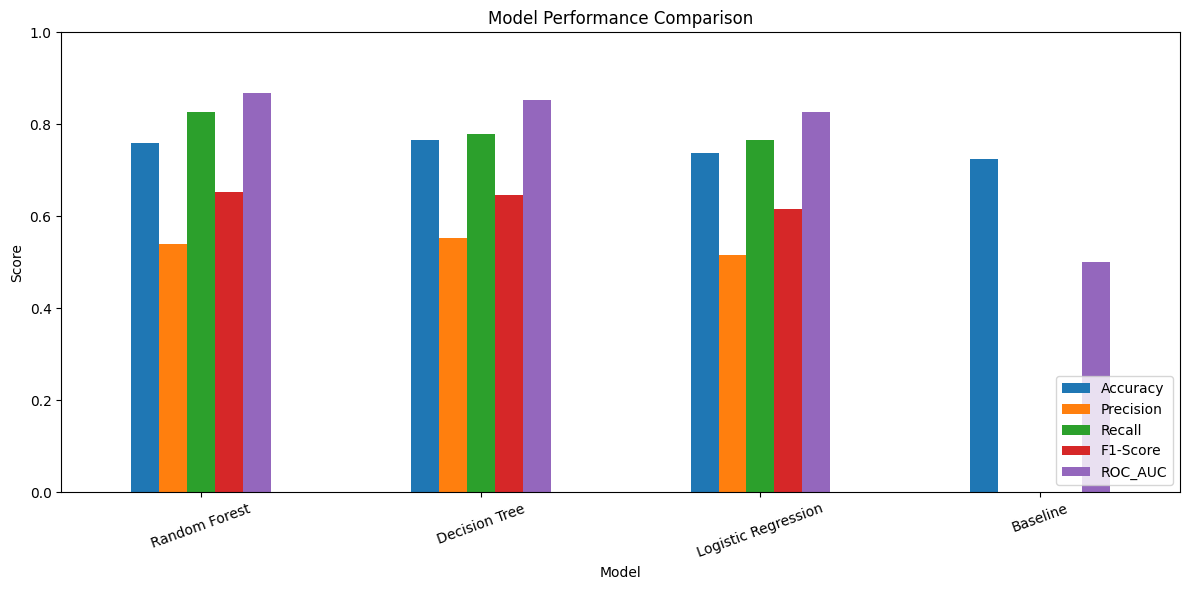

In [103]:
results_plot = results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC_AUC"]
]
results_plot.plot(kind="bar",figsize=(12,6))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=20)
plt.ylim(0,1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

#### Select the best model and tune its hyperparameters


Select Random Forest 
- It has the highest recall (82.69%), meaning it detects more actual cancellations
- It has the highest ROC_AUC (86.91%), meaining it distinguishes canceled and non canceled bookings better
- It has the highest F1-score, balancing precision and recall

Decision Tree has slightly higher accuracy, but for our business problem, detecting cancellations is particularly important

#### Prepare the Random Forest model

In [105]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(class_weight="balanced",random_state=42,n_jobs=1))
])

#### Define the hyperparameter search space

In [107]:
param_distributions = {
    "classifier__n_estimators": [100,150,200,250],
    "classifier__max_depth": [10,15,20,25,None],
    "classifier__min_samples_split": [2,5,10],
    "classifier__min_samples_leaf": [2,5,10],
    "classifier__max_features": ["sqrt","log2",0.5]
}

n_estimators:	Number of decision trees

max_depth:	Maximum depth of each tree

min_samples_split:	Minimum samples required to split a node

min_samples_leaf:	Minimum samples allowed in a leaf

max_features:	Number of features considered when splitting
#### Run RandomizedSearchCV

In [109]:
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    scoring="roc_auc",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=2
)
random_search.fit(X_train, y_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'classifier__max_depth': [10, 15, ...], 'classifier__max_features': ['sqrt', 'log2', ...], 'classifier__min_samples_leaf': [2, 5, ...], 'classifier__min_samples_split': [2, 5, ...], ...}"
,n_iter,10
,scoring,'roc_auc'
,n_jobs,-1
,refit,True
,cv,3
,verbose,2
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


#### Display the best parameters

In [111]:
print("Best Parameters: ", random_search.best_params_)
print("\nBest Cross-Validation ROC-AUC:", round(random_search.best_score_,4))

Best Parameters:  {'classifier__n_estimators': 150, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 5, 'classifier__max_features': 0.5, 'classifier__max_depth': None}

Best Cross-Validation ROC-AUC: 0.8798


#### Save the best model

In [112]:
best_model = random_search.best_estimator_
print("Best Random Forest Model:", best_model)

Best Random Forest Model: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputur',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['lead_time',
                                                   'stays_in_weekend_nights',
                                                   'stays_in_week_nights',
                                                   'adults', 'children',
                                                   'babies',
                                                   'is_repeated_guest',
                                                   'previous_cancellations',
                                       

#### Final model evaluation
Make predictions

In [113]:
# Predict cancellation classes
y_pred = best_model.predict(X_test)

# Predict cancellation probabilities
y_prob = best_model.predict_proba(X_test)[:,1]
print("Predictions:", y_pred[:10])
print("\nCancellation probabilities: ", y_prob[:10])

Predictions: [0 1 0 0 0 0 1 0 0 1]

Cancellation probabilities:  [0.34855303 0.58753654 0.04098378 0.00144683 0.         0.32499901
 0.65508507 0.01722953 0.01869968 0.89528414]


#### Calculate evaluation metrics

In [115]:
test_results = {
    "Accuracy": accuracy_score(y_test,y_pred),
    "Precision": precision_score(y_test,y_pred),
    "Recall": recall_score(y_test,y_pred),
    "F1-Score": f1_score(y_test,y_pred),
    "ROC-AUC": roc_auc_score(y_test,y_prob)
}

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

Accuracy: 0.8173
Precision: 0.6430
Recall: 0.7557
F1-Score: 0.6948
ROC-AUC: 0.8897


#### Generate the confusion matrix

Confusion Matrix:  [[10629  2015]
 [ 1173  3629]]


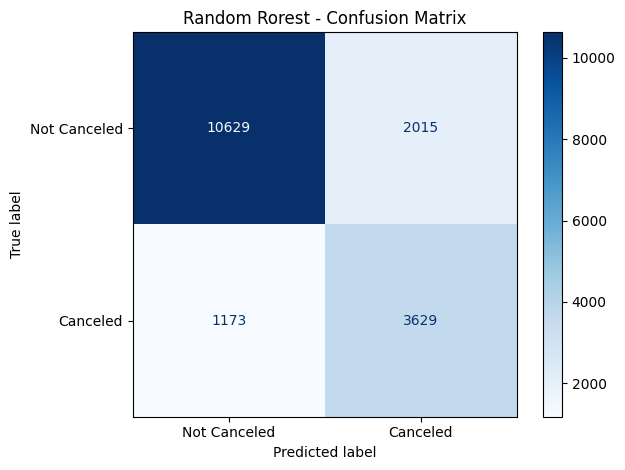

In [117]:
cm = confusion_matrix(y_test,y_pred)
print("Confusion Matrix: ",cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Canceled","Canceled"])
disp.plot(cmap="Blues")
plt.title("Random Rorest - Confusion Matrix")
plt.tight_layout()
plt.show()

## Error Analysis

The confusion matrix helps us understand the types of mistakes made by the model.

- False Positives: The model predicts cancellation, but the booking is not canceled. The hotel might request a deposit unnecessarily.
- False Negatives: The model predicts that a booking will not be canceled, but it is actually canceled. The hotel may lose an opportunity to manage the cancellation risk.

For this project, false negatives are particularly important because missed cancellations can result in lost revenue.

The model should therefore be evaluated using both recall and precision, rather than accuracy alone.

The matrix layout is [[True Negative, False Positive], [False Negative, True Positive]].
- True Negative: Correctly predicted a booking would not be canceled.
- False Positive: Predicted cancellation, but the booking was not canceled.
- False Negative: Missed a booking that was actually canceled.
- True Positive: Correctly detected a cancellation

false negatives are particularly important because they represent cancellations we failed to identify.

#### Display the classification report

In [119]:
print(classification_report(y_test,y_pred,target_names=["Not Cancelled","Canceled"]))

               precision    recall  f1-score   support

Not Cancelled       0.90      0.84      0.87     12644
     Canceled       0.64      0.76      0.69      4802

     accuracy                           0.82     17446
    macro avg       0.77      0.80      0.78     17446
 weighted avg       0.83      0.82      0.82     17446



#### Plot the ROC curve
This curve shows how well the model separates canceled bookings from non-canceled bookings at different classification thresholds.

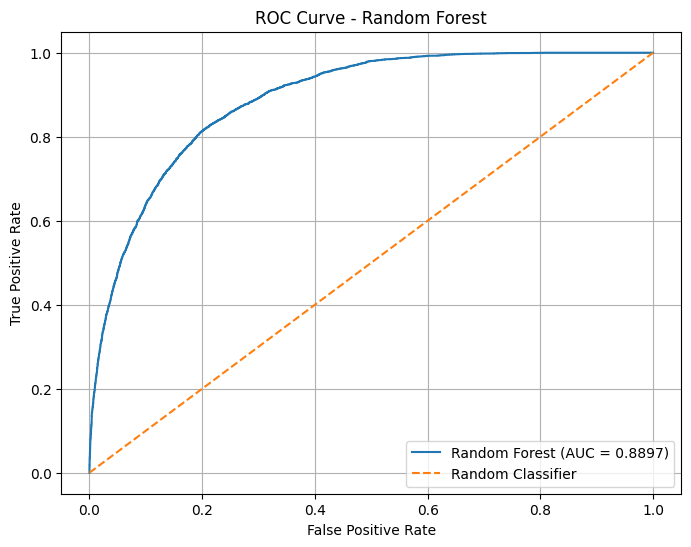

In [121]:
fpr, tpr, thresholds = roc_curve(y_test,y_prob)

roc_auc = auc(fpr,tpr)
plt.figure(figsize=(8,6))
plt.plot(fpr,tpr,label=f"Random Forest (AUC = {roc_auc:.4f})")
plt.plot([0,1],[0,1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.grid()
plt.show()

#### Compare cross-validation and test performance

In [122]:
print("Cross-validation ROC_AUC: ",round(random_search.best_score_,4))
print("Test ROC-AUC: ", round(roc_auc,4))

Cross-validation ROC_AUC:  0.8798
Test ROC-AUC:  0.8897


#### Compare different classification thresholds
- Prediction threshold (0.50): decides whether the model predicts Canceled or Not Canceled.

- Deposit thresholds (0.30 and 0.60): decide whether to recommend No Deposit, Partial Deposit, or Full Deposit.

In [124]:
thresholds_to_test = [0.3,0.4,0.5,0.6,0.7]
threshold_results = []
for threshold in thresholds_to_test:
    y_threshold_pred = (y_prob >= threshold).astype(int)
    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test,y_threshold_pred),
        "Precision": precision_score(y_test,y_threshold_pred),
        "Recall": recall_score(y_test,y_threshold_pred),
        "F1-Score": f1_score(y_test,y_threshold_pred)
    })
    
threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(4)

,Threshold,Accuracy,Precision,Recall,F1-Score
0,0.3,0.7436,0.5196,0.9086,0.6611
1,0.4,0.7900,0.5823,0.8394,0.6876
2,0.5,0.8173,0.6430,0.7557,0.6948
3,0.6,0.8269,0.6969,0.6568,0.6762
4,0.7,0.8249,0.7540,0.5400,0.6293


0.30: Best if we want to catch as many cancellations as possible.

0.40: A good compromise between recall and precision.

0.50: Gives the highest F1-score among the tested thresholds.

0.60–0.70: Better precision, but more actual cancellations are missed.
#### Visualize the threshold comparison

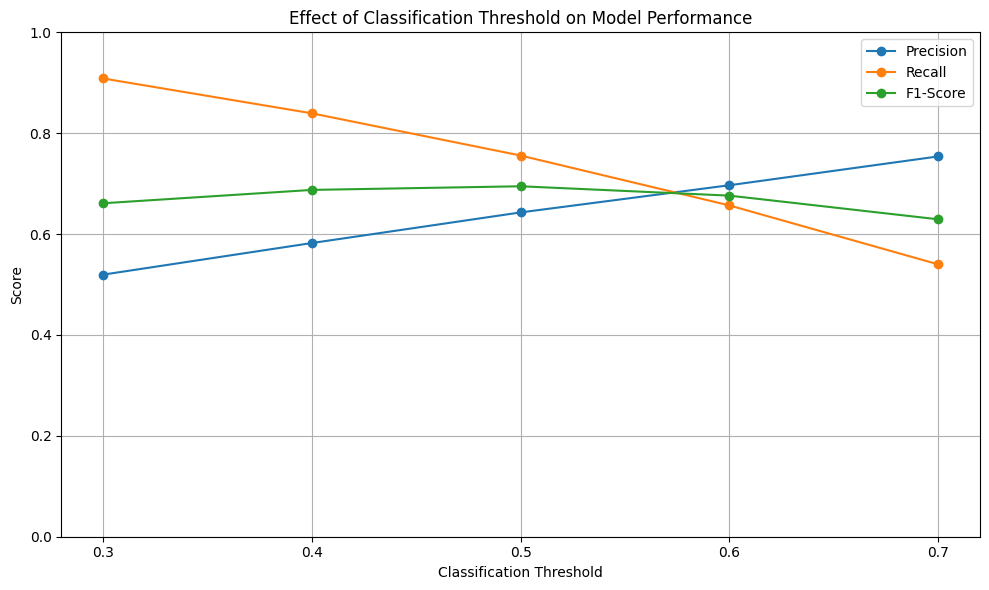

In [125]:
threshold_plot = threshold_df.set_index("Threshold")[
    ["Precision", "Recall", "F1-Score"]
]

threshold_plot.plot(
    marker="o",
    figsize=(10, 6)
)

plt.title("Effect of Classification Threshold on Model Performance")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.xticks(thresholds_to_test)
plt.ylim(0, 1)
plt.grid()
plt.tight_layout()
plt.show()

- Lower threshold: catches more cancellations, but increases false positives.

- Higher threshold: reduces false positives, but may miss more cancellations.

- A balanced threshold: tries to maintain a reasonable balance between precision and recall.
#### Connect probabilities to deposit recommendations
Our final project aims to recommend deposit policies, not just predict cancellations

- Below 30%:	No deposit
- 30%–59%:	Partial deposit
- 60% or above:	Full deposit
#### Create a recommendation function

In [126]:
def recommend_deposit(probability):
    if probability < 0.30:
        return "No Deposit"
    elif probability < 0.60:
        return "Partial Deposit"
    else:
        return "Full Deposit"

In [127]:
test_probabilities = [0.15,0.35,0.55,0.75,0.95]
for probability in test_probabilities:
    recommendation = recommend_deposit(probability)
    print(f"Cancellation Probability: {probability:.0%} --> {recommendation}")

Cancellation Probability: 15% --> No Deposit
Cancellation Probability: 35% --> Partial Deposit
Cancellation Probability: 55% --> Partial Deposit
Cancellation Probability: 75% --> Full Deposit
Cancellation Probability: 95% --> Full Deposit


#### Apply the recommendations to test bookings

In [128]:
recommendation_df = pd.DataFrame({
    "Actual Cancellation": y_test.values,
    "Cancellation Probability": y_prob,
    "Predicted Cancellation": y_pred
})
recommendation_df["Recommended Deposit"] = (recommendation_df["Cancellation Probability"].apply(recommend_deposit))
recommendation_df.head(10)

,Actual Cancellation,Cancellation Probability,Predicted Cancellation,Recommended Deposit
0,0,0.348553,0,Partial Deposit
1,1,0.587537,1,Partial Deposit
2,0,0.040984,0,No Deposit
3,0,0.001447,0,No Deposit
4,0,0.000000,0,No Deposit
5,0,0.324999,0,Partial Deposit
6,1,0.655085,1,Full Deposit
7,0,0.017230,0,No Deposit
8,0,0.018700,0,No Deposit
9,1,0.895284,1,Full Deposit


#### Analyze the deposit recommendation distribution

Recommended Deposit
No Deposit         9049
Full Deposit       4526
Partial Deposit    3871
Name: count, dtype: int64


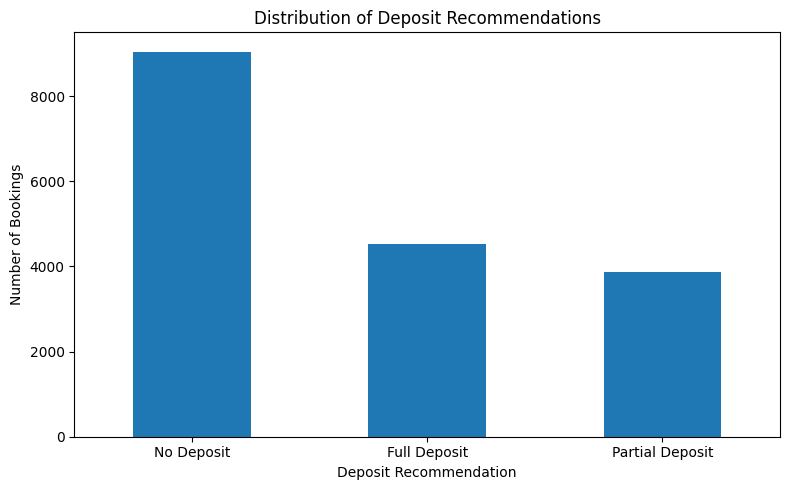

In [129]:
deposit_counts = recommendation_df["Recommended Deposit"].value_counts()
print(deposit_counts)
deposit_counts.plot(kind="bar",figsize=(8,5))

plt.title("Distribution of Deposit Recommendations")
plt.xlabel("Deposit Recommendation")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Evaluate the risk of each recommendation

In [130]:
risk_analysis = recommendation_df.groupby("Recommended Deposit", observed = False).agg(
    Total_Bookings=("Actual Cancellation", "count"),
    Actual_Cancellations=("Actual Cancellation", "sum"),
    Average_Predicted_Risk=("Cancellation Probability", "mean"),
    Actual_Cancellation_Rate=("Actual Cancellation", "mean")
)
risk_analysis["Actual_Cancellation_Rate"] *= 100
risk_analysis["Average_Predicted_Risk"] *= 100

risk_analysis = risk_analysis.round(2)

risk_analysis

,Total_Bookings,Actual_Cancellations,Average_Predicted_Risk,Actual_Cancellation_Rate
Recommended Deposit,,,,
Full Deposit,4526,3154,79.48,69.69
No Deposit,9049,439,8.72,4.85
Partial Deposit,3871,1209,43.94,31.23


#### Create a function to predict a new booking

Prediction function will:
1. Receive information about a new hotel booking.
2. Calculate its cancellation probability using best_model.
3. Predict whether it will be canceled using the 0.5 threshold.
4. Recommend a deposit policy using your three risk levels.

In [131]:
def predict_booking_cancellation(booking_data):
    #make sure all required features are provided
    missing_features = set(X_train.columns) - set(booking_data.keys())
    if missing_features:
        raise ValueError(f"Missing features: {missing_features}")
    
    #convert booking info to DataFrame
    new_booking = pd.DataFrame([booking_data], columns=X_train.columns)

    # predict cancellation probability
    cancellation_probability = best_model.predict_proba(new_booking)[0,1]

    predicted_cancellation = int(cancellation_probability >= 0.5)
    deposit_recommendation = recommend_deposit(cancellation_probability)

    return {
        "Cancellation Probability": round(cancellation_probability * 100, 2),
        "Predicted Cancellation": ("Canceled" if predicted_cancellation == 1 
                                   else "Not Canceled"),
                                   "Recommended Deposit":deposit_recommendation
    }

#### Test the function with a new booking

In [132]:
new_booking = {
    "hotel": "City Hotel",
    "lead_time": 120,
    "stays_in_weekend_nights": 2,
    "stays_in_week_nights": 3,
    "adults": 2,
    "children": 0,
    "babies": 0,
    "meal": "BB",
    "country": "PRT",
    "market_segment": "Online TA",
    "distribution_channel": "TA/TO",
    "is_repeated_guest": 0,
    "previous_cancellations": 1,
    "previous_bookings_not_canceled": 0,
    "reserved_room_type": "A",
    "customer_type": "Transient",
    "adr": 120.0,
    "required_car_parking_spaces": 0,
    "total_of_special_requests": 1,
    "arrival_day_of_week": 2,
    "arrival_month_num": 7,
    "total_nights": 5,
    "total_guests": 2
}

prediction = predict_booking_cancellation(new_booking)

for key, value in prediction.items():
    print(f"{key}: {value}")

Cancellation Probability: 97.86
Predicted Cancellation: Canceled
Recommended Deposit: Full Deposit


#### Save the trained model

In [134]:
joblib.dump(best_model,"hotel_cancellation_model.pkl")
print("Model saved successfully!")

Model saved successfully!


In [135]:
DEPOSIT_THRESHOLDS = {
    "no_deposit": 0.30,
    "partial_deposit": 0.60
}
joblib.dump(DEPOSIT_THRESHOLDS, "deposit_thresholds.pkl")

['deposit_thresholds.pkl']

#### Build the required Streamlit web app
Install Streamlit

In [137]:
%pip install streamlit

  Attempting uninstall: typing-extensions
    Found existing installation: typing-extensions 4.15.0
    Uninstalling typing-extensions-4.15.0:
      Successfully uninstalled typing-extensions-4.15.0
Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\hp\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.
